# 🏋️ Lesson 4: Model Training
**Week 6 · Notebook 4 of 10 · ⏱️ about 100 minutes**

---

## 🎯 Learning objectives
By the end of this lesson you will be able to:

1. **Explain** the roles of the **training**, **validation** and **test** sets, and why we need all three.
2. **Split** data correctly with scikit-learn (random, stratified, and three-way splits).
3. **Recognise and avoid data leakage**, including the subtle kind that sneaks in through preprocessing.
4. **Describe a training loop** (epochs, loss, parameter updates) and watch one run.
5. **Fit** a model, **predict** with it, and use a validation set to **choose between models**: touching the test set exactly once.

## 🗺️ Roadmap
`The exam analogy` → `Splitting data` → `Data leakage` → `Training loops` → `Model selection with a validation set` → **Problems**

In [1]:
import sys
sys.path.append("..")
from course_utils import *
setup()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

def rmse(y_true, y_pred):
    """Root mean squared error: the typical size of a prediction error, in the target's own units."""
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

---
# 📖 Part 1: The exam analogy

Picture a student preparing for a final exam.

| Stage | What the student does | In machine learning | Called the… |
|---|---|---|---|
| 📘 **Textbook problems** | studies worked examples and learns from the answers | the model learns its parameters | **Training set** |
| 📝 **Practice exam** | takes a mock test to see what's weak and adjust study plans | we compare models / tune hyperparameters | **Validation set** |
| 🎓 **Final exam** | one sitting; the grade counts; no retakes | the final, honest performance report | **Test set** |

Now suppose the teacher leaks the final-exam questions beforehand. The student memorises them and scores 100%, and we conclude they're brilliant. **But we've learned nothing about whether they understand the subject.**

> 🔑 **The most important sentence in this lesson:** *a model's performance only means something when measured on data it has never seen: not for fitting, not for tuning, not for anything.*

If we reuse data for both **learning** and **evaluating**, our performance estimate becomes **optimistic and dishonest**. Splitting the data is how we protect ourselves.

| Set | Used for | How often we peek |
|---|---|---|
| **Train** (≈60–80%) | fitting parameters | constantly |
| **Validation** (≈10–20%) | choosing models & hyperparameters | many times |
| **Test** (≈10–20%) | reporting final performance | **once** |

---
# 📖 Part 2: Splitting data with scikit-learn

## 2.1 A simple train / test split

In [2]:
housing = load("housing.csv")
X = housing.drop(columns="price_k")
y = housing["price_k"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20% held out for testing
    random_state=42)      # makes the shuffle reproducible (same split every run)

print(f"all data : {len(X)} houses")
print(f"train    : {len(X_train)}  ({len(X_train)/len(X):.0%})")
print(f"test     : {len(X_test)}  ({len(X_test)/len(X):.0%})")

all data : 900 houses
train    : 720  (80%)
test     : 180  (20%)


Three things to notice:

1. **Order of outputs:** `X_train, X_test, y_train, y_test`: always this order.
2. **Shuffling:** by default rows are **shuffled** first. (If your file is sorted (say, by date or by price) an unshuffled split would give you a test set that looks nothing like your training set.)
3. **`random_state`:** any fixed integer makes the "random" shuffle repeatable, so your results, and your bug reports, are reproducible. The number itself doesn't matter (42 is a programmer's in-joke).

## 2.2 Stratified splits: when classes are rare

Our `churn` data has only ~15% churners. With a purely random split, the *test set* could by bad luck contain 12% churners, or 19%. Let's see how much the churn rate wobbles across different shuffles:

In [3]:
churn = load("churn.csv")

plain, strat = [], []
for seed in range(8):
    _, te = train_test_split(churn, test_size=0.2, random_state=seed)
    plain.append(te["churned"].mean())
    _, te = train_test_split(churn, test_size=0.2, random_state=seed, stratify=churn["churned"])
    strat.append(te["churned"].mean())

print("overall churn rate:", round(churn["churned"].mean(), 3))
print("test-set churn rate, plain random split :", np.round(plain, 3))
print("test-set churn rate, stratified split   :", np.round(strat, 3))

overall churn rate: 0.152
test-set churn rate, plain random split : [0.143 0.12  0.153 0.13  0.157 0.187 0.133 0.17 ]
test-set churn rate, stratified split   : [0.153 0.153 0.153 0.153 0.153 0.153 0.153 0.153]


With `stratify=y`, scikit-learn keeps the class proportions **identical in every split**. The plain split bounces around (≈12% to 19%): enough to make a model's measured performance look better or worse than it truly is. **Rule: for classification, always stratify** (especially with imbalanced classes).

## 2.3 Three-way split: train / validation / test

`train_test_split` only cuts in two, so we call it **twice**:

### 🧑‍🏫 Worked Example 1: A 60 / 20 / 20 split of 900 houses

*Plan:* first cut off the test set (20% of 900 = 180). The remaining 720 are split again; I want 180 validation houses, which is **180 / 720 = 25%** of what's left, so the second `test_size` is **0.25**, *not* 0.2. (A classic arithmetic trap!)

In [4]:
# Step 1: set the TEST set aside first.  Lock it away.
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.20, random_state=0)

# Step 2: split the rest into TRAIN and VALIDATION.   0.25 of 720 = 180 = 20% of the original 900.
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=0)

for name, part in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"{name:<11}: {len(part):>3} houses ({len(part)/len(X):.0%})")

train      : 540 houses (60%)
validation : 180 houses (20%)
test       : 180 houses (20%)


**How big should each split be?**

| Dataset size | Typical strategy |
|---|---|
| **Small** (hundreds) | validation is too small to trust → use **cross-validation** instead (Lesson 5) |
| **Medium** (thousands) | 60/20/20 or 70/15/15 |
| **Huge** (millions) | 98/1/1 is fine: 1% of a million is still 10,000 examples |

---
# 📖 Part 3: Data leakage: the silent killer

**Data leakage** means information from outside the training set (usually the test set, or the answer itself) sneaks into model building. The model then looks wonderful in your notebook and fails in the real world. There are two main flavours.

## 3.1 Preprocessing leakage

Imagine you standardise your features using `StandardScaler().fit_transform(X)` **on the whole dataset** *before* splitting. The scaler's mean and standard deviation then include test-set rows, so the training pipeline has secretly "seen" test data. The effect is often small, but it is *wrong in principle*, and in some situations (small data, outliers, feature selection) it's large.

✅ **The right way:** *fit* every preprocessing step on the **training data only**, then merely *apply* it to validation/test data.

In [5]:
# ❌ WRONG: scaler learns mean/std from ALL rows, including future test rows
scaler_bad = StandardScaler().fit(X)

# ✅ RIGHT: learn mean/std from training rows only, then reuse them on new data
scaler = StandardScaler().fit(X_train)            # fit  : learn the mean & std  (training only!)
X_train_s = scaler.transform(X_train)             # transform: apply
X_test_s  = scaler.transform(X_test)              # transform: apply the TRAINING statistics to test data

print("mean of area_sqm in the training rows:", round(X_train["area_sqm"].mean(), 2))
print("mean the scaler learned              :", round(scaler.mean_[0], 2))

mean of area_sqm in the training rows: 119.31
mean the scaler learned              : 119.31


> 🛡️ **The easy way to never get this wrong:** scikit-learn's `Pipeline`. `make_pipeline(StandardScaler(), model).fit(X_train, y_train)` fits the scaler *and* the model on the training data only. Calling `.predict(X_test)` automatically applies the already-learned scaling. Use a pipeline for everything.

## 3.2 Target leakage

This is the dramatic kind: a feature that **contains or is derived from the answer**, or won't be known when you actually need the prediction.

> *Story:* a hospital model predicting "will this patient develop pneumonia?" achieved 99% accuracy. Why? One feature was *"prescribed pneumonia antibiotics"*, which doctors only prescribe **after** diagnosing pneumonia. The model learned to read the doctors' minds, not the patients' bodies.

Let's recreate this with houses. Suppose someone adds a column **`monthly_mortgage_usd`**: the bank's monthly payment on the sale price. It's computed *from the price*, so it's the answer in disguise (and nobody has a mortgage payment *before* the house's price is known!).

In [6]:
rng = np.random.default_rng(0)
leaky = housing.copy()
leaky["monthly_mortgage_usd"] = (leaky["price_k"] * 1000 * 0.0056 * (1 + rng.normal(0, 0.01, len(leaky)))).round(0)

def fit_and_score(df, label):
    Xa, ya = df.drop(columns="price_k"), df["price_k"]
    Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.2, random_state=0)
    pred = LinearRegression().fit(Xtr, ytr).predict(Xte)
    print(f"{label:<28} test RMSE = {rmse(yte, pred):6.1f}   (in $1000s)    R² = {r2_score(yte, pred):.4f}")

fit_and_score(housing, "honest features")
fit_and_score(leaky,   "with the leaky mortgage col")

honest features              test RMSE =   30.9   (in $1000s)    R² = 0.9715
with the leaky mortgage col  test RMSE =    5.1   (in $1000s)    R² = 0.9992


The leaky model's error collapses by a factor of six and R² touches 0.999. **Too good to be true, and it is.** In production, the mortgage column would not exist at prediction time and the model would collapse.

**A detective's checklist for leakage:**

1. **Suspiciously great performance?** Investigate before celebrating.
2. **For every feature ask:** *"Will I truly know this at the moment I need to make a prediction?"*
3. **Look at feature importances / correlations:** one feature with near-perfect correlation to the target is a red flag.
4. **Split first, then do everything else** (scaling, imputing, feature selection) using the training data only.

---
# 📖 Part 4: Training loops: what `fit` is really doing

When you call `model.fit(X, y)`, many algorithms run a **loop**:

```
initialise the parameters (often randomly or at zero)
repeat for each epoch  (one epoch = one pass through the training data):
    1. predict: use the current parameters to make predictions
    2. measure loss: how wrong are the predictions?          (Lesson 8)
    3. update: nudge parameters to reduce the loss    (Lesson 8: gradient descent)
    4. log: record training and validation error
stop when the loss stops improving (convergence) or we run out of epochs
```

Linear regression can be solved in one shot with algebra, but most models (neural nets, logistic regression on huge data, gradient boosting) need this loop. scikit-learn exposes it in models like **`SGDRegressor`** through `partial_fit`: "do *one* pass of learning and wait for me." That lets us write the loop ourselves and **watch learning happen**.

### 🧑‍🏫 Worked Example 2: Watching a model learn, epoch by epoch

We'll predict exam scores from the four student features, tracking the error on **both** the training data and a held-out validation set after each epoch.

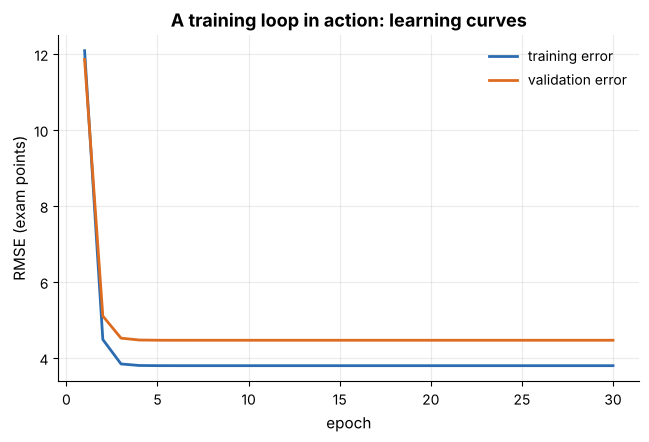

epoch 1 : validation RMSE = 11.86
epoch 30: validation RMSE = 4.47


In [7]:
students = load("students.csv")
Xs, ys = students.drop(columns="exam_score"), students["exam_score"]
Xtr, Xval, ytr, yval = train_test_split(Xs, ys, test_size=0.2, random_state=0)

scaler = StandardScaler().fit(Xtr)                 # fit on training data only
Xtr_s, Xval_s = scaler.transform(Xtr), scaler.transform(Xval)

model = SGDRegressor(learning_rate="constant", eta0=0.01, penalty=None, random_state=0)

train_curve, val_curve = [], []
for epoch in range(1, 31):
    model.partial_fit(Xtr_s, ytr)                  # ONE pass over the training data  (predict → loss → update)
    train_curve.append(rmse(ytr,  model.predict(Xtr_s)))
    val_curve.append(  rmse(yval, model.predict(Xval_s)))

plt.plot(range(1, 31), train_curve, color=BLUE,   lw=2, label="training error")
plt.plot(range(1, 31), val_curve,   color=ORANGE, lw=2, label="validation error")
plt.xlabel("epoch"); plt.ylabel("RMSE (exam points)"); plt.title("A training loop in action: learning curves")
plt.legend(); plt.show()
print(f"epoch 1 : validation RMSE = {val_curve[0]:.2f}")
print(f"epoch 30: validation RMSE = {val_curve[-1]:.2f}")

Read the plot like a doctor reads an ECG:

* **Epoch 1:** large error: the parameters started at zero, knowing nothing.
* **Epochs 2–5:** error plunges: the model is learning fast.
* **After ~5 epochs:** the curves go flat. This is **convergence**: more passes don't help, because the model has already found essentially the best straight-line fit. (The leftover error, ~4.5 points, is the *irreducible noise* in the data.)

For richer models (Lesson 5) you'll see something more dramatic: the **training** error keeps falling while the **validation** error turns *upward*. That's the signature of **overfitting**, and watching for it is how we know when to stop: **early stopping**.

> 🔁 **Key words, decoded.** *Epoch* = one full pass over the training set. *Iteration* = one parameter update (with mini-batches, an epoch has many iterations). *Convergence* = the loss has stopped meaningfully improving.

---
# 📖 Part 5: Model selection with a validation set

Now we can finally answer the question we raised in Lesson 1: **which value of the hyperparameter *k* is best for a KNN regressor?** And we can do it *honestly*.

### 🧑‍🏫 Worked Example 3: Choosing *k* the right way

**My plan:**
1. Use the 60/20/20 split from before.
2. For each candidate *k*, **train on the training set**, measure error on the **validation** set.
3. Pick the *k* with the lowest validation error.
4. **Only then**, evaluate that one chosen model on the **test set**: once, and report it.

validation RMSE by k: {1: 83.0, 2: 73.5, 3: 68.5, 5: 63.3, 8: 65.7, 12: 67.8, 20: 69.1, 40: 73.0, 80: 82.4}

→ best k on validation data: 5


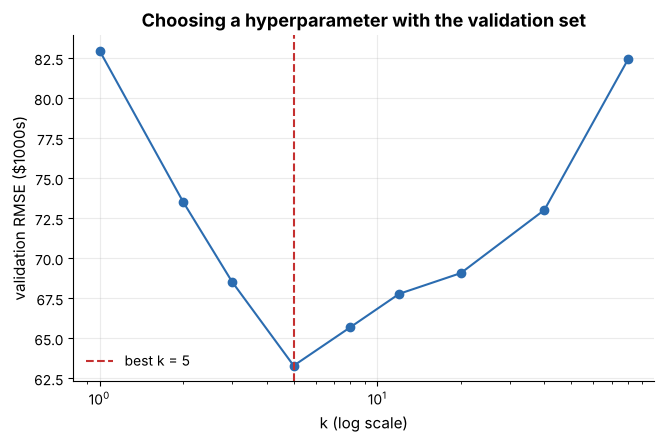

In [8]:
candidates = [1, 2, 3, 5, 8, 12, 20, 40, 80]
val_rmse = {}
for k in candidates:
    pipe = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))   # scaler + model in one object
    pipe.fit(X_train, y_train)                                                    # TRAIN
    val_rmse[k] = rmse(y_val, pipe.predict(X_val))                                # VALIDATE

best_k = min(val_rmse, key=val_rmse.get)
print("validation RMSE by k:", {k: round(v, 1) for k, v in val_rmse.items()})
print(f"\n→ best k on validation data: {best_k}")

plt.plot(list(val_rmse), list(val_rmse.values()), "o-", color=BLUE)
plt.axvline(best_k, color=RED, ls="--", label=f"best k = {best_k}")
plt.xscale("log"); plt.xlabel("k (log scale)"); plt.ylabel("validation RMSE ($1000s)")
plt.title("Choosing a hyperparameter with the validation set"); plt.legend(); plt.show()

In [9]:
# The ONE and ONLY look at the test set:
final = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=best_k)).fit(X_train, y_train)
print(f"Validation RMSE (used to choose k): {val_rmse[best_k]:.1f}")
print(f"TEST RMSE (honest final report)   : {rmse(y_test, final.predict(X_test)):.1f}   (in $1000s)")

Validation RMSE (used to choose k): 63.3
TEST RMSE (honest final report)   : 70.8   (in $1000s)


Why not just choose *k* by looking at the test set? Because once we pick the winner **using** the test set, the test set is no longer a fair exam (it has influenced a decision. It's subtle, but with many experiments you'd unknowingly overfit *to the test set* itself. Hence the discipline: **validation for choosing, test for reporting) once.**

> 💡 Often, after choosing hyperparameters, you **retrain on train + validation together** (more data = better model) and then evaluate on the test set once. Either way, the test set stays untouched until the very end.

## The scikit-learn pattern you'll use forever

```python
model = SomeModel(hyperparameter=value)      # 1. create (choose hyperparameters)
model.fit(X_train, y_train)                  # 2. train: learns parameters from TRAINING data only
predictions = model.predict(X_val)           # 3. predict: on data it has NOT seen
score = metric(y_val, predictions)           # 4. evaluate against the true answers
```

### ⚠️ Pitfall gallery

| 🙅 Mistake | Why it hurts | 🙆 Fix |
|---|---|---|
| Evaluating on training data | measures memory, not skill | evaluate on held-out data |
| Tuning on the test set | test set stops being "unseen" | tune on validation / cross-validation |
| Fitting the scaler on all data | leaks test statistics | fit on train only, or use `Pipeline` |
| Not shuffling sorted data | splits don't represent each other | keep `shuffle=True` (default) |
| Forgetting `stratify` | rare classes vanish from a split | `stratify=y` for classification |
| Features unavailable at prediction time | model unusable in production | ask *"will I know this then?"* |
| Forgetting `random_state` | irreproducible results | always set one |

---
# 🧩 Your turn: Problems

### 🧩 Problem 4.1: The classic 80 / 20 split &nbsp; ⭐

Split `students.csv` into train and test sets. The target is `exam_score`; all other columns are features.

Use `test_size=0.2` and `random_state=42`, and name the four pieces `X_train, X_test, y_train, y_test`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`train_test_split(X, y, test_size=..., random_state=...)` returns four objects in the order *X_train, X_test, y_train, y_test*.

</details>

In [ ]:
students = load("students.csv")
X = students.drop(columns="exam_score")
y = students["exam_score"]

# split here

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("160 training rows", lambda: len(X_train) == 160 and len(y_train) == 160)
check("40 test rows", lambda: len(X_test) == 40 and len(y_test) == 40)
check("no row appears in both sets", lambda: len(set(X_train.index) & set(X_test.index)) == 0)
check("features and target stay aligned", lambda: (X_train.index == y_train.index).all())

### 🧩 Problem 4.2: Stratify the churners &nbsp; ⭐⭐

Split `churn.csv` (target: `churned`) into train and test sets with `test_size=0.25`, `random_state=1`, **stratified on the target**.

Name them `X_train, X_test, y_train, y_test` and also compute the churn rate in each set: `rate_train`, `rate_test`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Pass `stratify=y` to `train_test_split`.

</details>

<details>
<summary>💡 Hint 2</summary>

The churn rate of a 0/1 target is simply its mean: `y_train.mean()`.

</details>

In [ ]:
churn = load("churn.csv")
X = churn.drop(columns="churned")
y = churn["churned"]

rate_train = rate_test = None
print(rate_train, rate_test)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("test set is 25% of the data", lambda: len(X_test) == 375)
check("churn rates in train and test differ by < 0.2 percentage points", lambda: abs(rate_train - rate_test) < 0.002)
check("both rates match the overall rate", lambda: abs(rate_train - y.mean()) < 0.003)

### 🧩 Problem 4.3: Three-way split &nbsp; ⭐⭐

Split `housing.csv` (target: `price_k`) into **train 60% / validation 20% / test 20%** with two calls to `train_test_split`, using `random_state=0` both times.

Name the pieces `X_train, X_val, X_test, y_train, y_val, y_test`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

First split off the test set with `test_size=0.2`.

</details>

<details>
<summary>💡 Hint 2</summary>

The second split is on the remaining 80%; to get 20% of the *original* you need `test_size=0.25` (since 0.25 × 0.8 = 0.2).

</details>

In [ ]:
housing = load("housing.csv")
X = housing.drop(columns="price_k")
y = housing["price_k"]

# split twice

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("train has 540 rows (60%)", lambda: len(X_train) == 540)
check("validation has 180 rows (20%)", lambda: len(X_val) == 180)
check("test has 180 rows (20%)", lambda: len(X_test) == 180)
check("the three sets are disjoint", lambda: len(set(X_train.index) | set(X_val.index) | set(X_test.index)) == 900)

### 🧩 Problem 4.4: Choose k with validation, report with test &nbsp; ⭐⭐

Below we give you a ready-made three-way split of the **housing** data. Your job:

1. For each `k` in `[1, 3, 5, 10, 20, 50]` train `make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))` on the **training** set and compute the **validation RMSE**. Store them in `val_rmse` (`{k: rmse}`).
2. Store the winning *k* in `best_k`, and its fitted pipeline in `best_model`.
3. Compute the **test RMSE** of `best_model` and store it in `test_rmse`.

*(Use the `rmse(y_true, y_pred)` helper defined at the top of this notebook.)*

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Loop over the candidates, `fit` on `X_train, y_train`, and call `rmse(y_val, model.predict(X_val))`.

</details>

<details>
<summary>💡 Hint 2</summary>

`best_k = min(val_rmse, key=val_rmse.get)`. Keep the best fitted pipeline by storing it when you find a new minimum, or just refit it afterwards.

</details>

<details>
<summary>💡 Hint 3</summary>

`test_rmse = rmse(y_test, best_model.predict(X_test))`: and only compute it **after** choosing `best_k`.

</details>

In [ ]:
housing = load("housing.csv")
X = housing.drop(columns="price_k"); y = housing["price_k"]
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.20, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=0)

val_rmse = {}
best_k = None
best_model = None
test_rmse = None

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("validation RMSE recorded for 6 values of k", lambda: sorted(val_rmse) == [1, 3, 5, 10, 20, 50])
check("best_k really has the lowest validation RMSE", lambda: best_k == min(val_rmse, key=val_rmse.get))
check("test RMSE matches best_model", lambda: abs(test_rmse - rmse(y_test, best_model.predict(X_test))) < 1e-9)
check("test RMSE is in the same ballpark as validation RMSE", lambda: 0.5 * val_rmse[best_k] < test_rmse < 2 * val_rmse[best_k])

### 🧩 Problem 4.5: Catch the leak &nbsp; ⭐⭐

Detective time. The DataFrame `leaky_df` below is the housing data plus two new columns: `listing_id` (a random ID) and `monthly_mortgage_usd`. One of the columns **leaks** the target.

1. Find the leaky column and store its name in `leaky_col` (hint: look at each feature's **correlation with `price_k`**, *and* ask whether it would be known before the sale).
2. Using `train_test_split(..., test_size=0.2, random_state=0)` and a `LinearRegression`, compute the test **R²** *with* all features → `leaky_r2`, and *without* the leaky column → `honest_r2`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`leaky_df.corr()["price_k"].abs().sort_values()` ranks columns by how strongly they track the price.

</details>

<details>
<summary>💡 Hint 2</summary>

A feature with correlation ≈ 1.0 *and* a logical reason why it couldn't exist before the sale is the culprit.

</details>

<details>
<summary>💡 Hint 3</summary>

`r2_score(y_test, model.predict(X_test))` gives R² on the test set.

</details>

In [ ]:
rng = np.random.default_rng(0)
leaky_df = load("housing.csv")
leaky_df["listing_id"] = rng.integers(10_000, 99_999, len(leaky_df))
leaky_df["monthly_mortgage_usd"] = (leaky_df["price_k"] * 1000 * 0.0056 * (1 + rng.normal(0, 0.01, len(leaky_df)))).round(0)

leaky_col = None
leaky_r2 = honest_r2 = None
print(leaky_col, leaky_r2, honest_r2)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("identified the leaky column", lambda: leaky_col == "monthly_mortgage_usd")
check("leaky model looks 'too good' (R² > 0.995)", lambda: leaky_r2 > 0.995)
check("honest model is lower but still good (0.90 < R² < 0.995)", lambda: 0.90 < honest_r2 < 0.995)

### 🧩 Problem 4.6: Write your own training loop &nbsp; ⭐⭐⭐

Reproduce the learning-curve experiment yourself. The data is prepared for you (scaled student features, with a train/validation split).

1. Create `SGDRegressor(learning_rate="constant", eta0=0.01, penalty=None, random_state=0)`.
2. Loop for **30 epochs**: call `partial_fit(X_tr, y_tr)` once per epoch, then append the **validation RMSE** to the list `val_curve`.
3. Store the epoch (1-based) at which the validation error was lowest in `best_epoch`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`partial_fit` performs a single pass of learning each time you call it: exactly one epoch.

</details>

<details>
<summary>💡 Hint 2</summary>

After each `partial_fit`, compute `rmse(y_va, model.predict(X_va))` and `append` it.

</details>

<details>
<summary>💡 Hint 3</summary>

`np.argmin(val_curve)` is the 0-based position of the minimum; add 1 for an epoch number.

</details>

In [ ]:
students = load("students.csv")
Xs, ys = students.drop(columns="exam_score"), students["exam_score"]
Xa, Xb, y_tr, y_va = train_test_split(Xs, ys, test_size=0.2, random_state=0)
sc = StandardScaler().fit(Xa)
X_tr, X_va = sc.transform(Xa), sc.transform(Xb)

val_curve = []
best_epoch = None
# your training loop here
print(len(val_curve), best_epoch)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("30 epochs recorded", lambda: len(val_curve) == 30)
check("error decreased overall (epoch 30 beats epoch 1)", lambda: val_curve[-1] < val_curve[0])
check("converged to a small error (< 5.5 points)", lambda: val_curve[-1] < 5.5)
check("best_epoch is the argmin (1-based)", lambda: best_epoch == int(np.argmin(val_curve)) + 1)

---
## 🎟️ Exit ticket

**Q1.** What is each of the training, validation and test sets used for?
**Q2.** You have 1,000 rows. You want 70/15/15. What `test_size` do you pass in the second split?
**Q3.** Why should the scaler be fitted on the training data only?
**Q4.** Your model gets R² = 0.999 on its first try. What are the first three things you do?
**Q5.** What is an epoch? What does it mean when the training curve flattens?

<details><summary>👀 Answers</summary>

**A1.** Train: learn parameters. Validation: compare models/tune hyperparameters. Test: one final, honest performance estimate.
**A2.** First split off 15% for test (850 rows remain); the validation set must be 150 rows = 150/850 ≈ **0.176** of what's left.
**A3.** Otherwise statistics from test rows influence the training process (preprocessing leakage), making the evaluation optimistic.
**A4.** Be suspicious: check for target leakage (features derived from or known only after the target), check that you didn't evaluate on training data, and check for duplicates between train and test.
**A5.** One full pass over the training data. A flat curve means convergence: additional passes no longer reduce the loss meaningfully.

</details>

---
## 📌 Recap: Lesson 4 on one page

* **Train** to learn · **validation** to choose · **test** to report (once). Never judge a model on data it trained on.
* `train_test_split(X, y, test_size, random_state, stratify=y)`; for three sets, split twice (mind the second fraction!).
* **Stratify** classification splits. **Shuffle** unless the data is time-ordered.
* **Leakage** = information the model shouldn't have. Fit preprocessing on **train only** (use `Pipeline`); ask *"will I know this feature at prediction time?"*
* **Training loop:** predict → loss → update → repeat; **epoch** = one pass; **convergence** = loss stops improving. `partial_fit` lets you run it by hand.
* **Model selection:** loop over candidates on train → pick the best by validation → evaluate on test once.

**Next up →** `05_model_generalization.ipynb`: *why* models that ace the training set can flop on new data, and how to prevent it.